# Commit Risk Predictor: analysis

This notebook explains **why** the project is built the way it is: what the data looks like,
which pitfalls the evaluation avoids, and how much the model can be trusted.
The production code lives in `src/commit_risk/`; here we only use it.

Dataset: every non-merge, non-release commit of [vtex/faststore](https://github.com/vtex/faststore)
that touches code, labeled with the SZZ algorithm (`introduced_bug = 1` when a later `fix:`
commit changed lines it wrote).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from commit_risk.features import TARGET, to_model_input
from commit_risk.train import (
    bugs_caught,
    build_baseline,
    build_forest,
    drop_immature_labels,
    temporal_split,
)

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "grid.alpha": 0.3})

raw = pd.read_csv("../data/faststore_commits.csv", parse_dates=["date"])
print(f"{len(raw):,} commits from {raw.date.min():%Y-%m} to {raw.date.max():%Y-%m}")
raw.head(3)

2,437 commits from 2020-06 to 2026-11


,hash,date,subject,lines_added,lines_deleted,n_files,n_dirs,n_subsystems,entropy,n_test_files,...,prior_changes,prior_fixes,avg_file_age_days,author_experience,author_subsystem_experience,is_fix,commit_type,hour,weekday,introduced_bug
0,cd2f1ac35c83034401cbd6add2668172156b6ca6,2020-06-16,adding files,2499,0,39,13,5,0.9149,0,...,0,0,0.0,0,0,0,other,0,1,0
1,0ee81960f6c5f283dd3976790e0464ff96f55973,2020-06-17,add gatsby,2890,2499,90,32,8,0.9289,0,...,39,0,1.9,0,0,0,other,21,2,1
2,407a89a5f72bbe09861c10b788c9f3f8eeedcfac,2020-06-18,add client only,134,49,5,3,1,0.8679,0,...,3,0,0.2,1,1,0,other,1,3,0


## 1. How common are bug-introducing commits?

About a third of the commits wrote lines that a later fix had to change. The classes are
imbalanced, so accuracy alone would be misleading: we use ROC AUC and "bugs caught" instead.

In [2]:
raw[TARGET].value_counts(normalize=True).rename({0: "clean", 1: "introduced a bug"}).round(3)

introduced_bug
clean               0.639
introduced a bug    0.361
Name: proportion, dtype: float64

## 2. Does the size of a change matter?

Splitting commits into five equal groups by changed lines shows a strong, steady relationship.

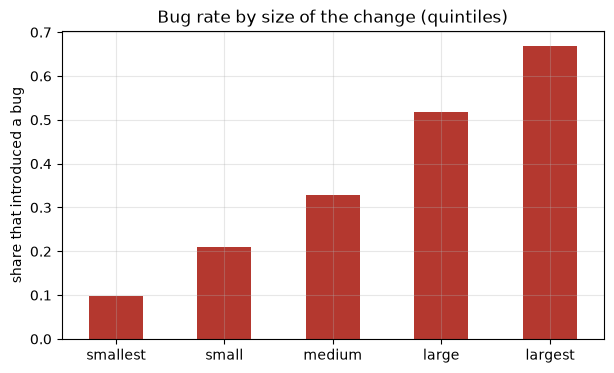

smallest    0.10
small       0.21
medium      0.33
large       0.52
largest     0.67
Name: introduced_bug, dtype: float64

In [3]:
size = raw["lines_added"] + raw["lines_deleted"]
labels = ["smallest", "small", "medium", "large", "largest"]
by_size = raw.groupby(pd.qcut(size, 5, labels=labels), observed=True)[TARGET].mean()

by_size.plot(kind="bar", color="#b4382f", rot=0)
plt.ylabel("share that introduced a bug")
plt.title("Bug rate by size of the change (quintiles)")
plt.show()
by_size.round(2)

## 3. Does the commit type matter?

`feat` commits introduce bugs far more often than `fix` or `chore`, which matches intuition:
new behaviour is where untested paths appear.

In [4]:
(
    raw.groupby("commit_type")[TARGET]
    .agg(commits="count", bug_rate="mean")
    .query("commits >= 30")
    .sort_values("bug_rate", ascending=False)
    .round(2)
)

,commits,bug_rate
commit_type,,
feat,469,0.61
docs,57,0.42
fix,523,0.34
chore,159,0.32
other,1142,0.29
refactor,42,0.26


## 4. Why the newest commits are dropped

A bug is only labeled once someone fixes it, which can take months, so the newest commits can look
artificially "clean". Training on them would teach the model that recent commits are safe.
The last 180 days are therefore removed (`drop_immature_labels`).

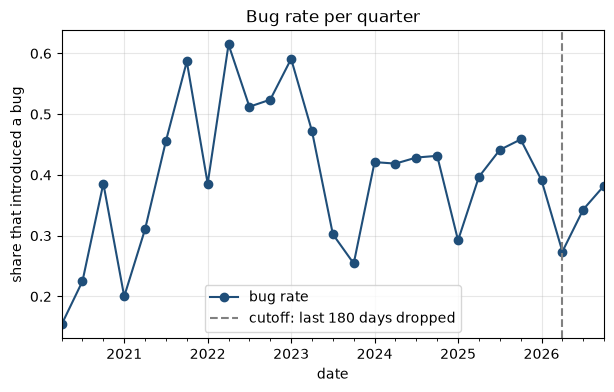

In [5]:
monthly = raw.set_index("date")[TARGET].resample("QE").mean()
cutoff = raw.date.max() - pd.Timedelta(days=180)

monthly.plot(marker="o", color="#1f4e79", label="bug rate")
plt.axvline(cutoff, color="gray", ls="--", label="cutoff: last 180 days dropped")
plt.ylabel("share that introduced a bug")
plt.title("Bug rate per quarter")
plt.legend()
plt.show()

In FastStore the effect is mild: the last quarters stay close to the historical average, which
suggests bugs here are usually fixed within weeks. The cutoff costs a few hundred commits and
protects the evaluation in repositories where fixes take longer. It is computed relative to the
newest commit, so it stays correct when the dataset is rebuilt later.

## 5. Why the split must follow time

A random split lets the model train on commits from the *future* of the test commits, which never
happens in real life. Comparing both splits on the same data shows how optimistic the wrong one is.

In [6]:
df = drop_immature_labels(raw.assign(date=raw.date.dt.strftime("%Y-%m-%d")))


def auc_for(train, test):
    model = build_baseline()
    X_train = to_model_input(train)
    model.fit(X_train, train[TARGET])
    X_test = to_model_input(test, list(X_train.columns))
    return roc_auc_score(test[TARGET], model.predict_proba(X_test)[:, 1])


shuffled = df.sample(frac=1, random_state=0)
cut = int(len(df) * 0.8)
train_t, test_t = temporal_split(df)
print(f"random split:   AUC = {auc_for(shuffled.iloc[:cut], shuffled.iloc[cut:]):.3f}")
print(f"temporal split: AUC = {auc_for(train_t, test_t):.3f}  <- what we report")

random split:   AUC = 0.817
temporal split: AUC = 0.753  <- what we report


The random split reports a much better model (about 0.82) than the temporal one (about 0.75).
That gap is optimism, not skill: with shuffled data the model sees commits from the same weeks,
authors and files on both sides of the split, and the project changes over time (team, codebase,
conventions). Only the temporal number tells what to expect on next month's commits.

## 6. Baseline vs Random Forest

In [7]:
X_train = to_model_input(train_t)
X_test = to_model_input(test_t, list(X_train.columns))
y_train, y_test = train_t[TARGET], test_t[TARGET].reset_index(drop=True)

models = {"Logistic Regression": build_baseline(), "Random Forest": build_forest()}
risk = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    risk[name] = model.predict_proba(X_test)[:, 1]
    print(f"{name:<20} AUC = {roc_auc_score(y_test, risk[name]):.3f}")

Logistic Regression  AUC = 0.753


Random Forest        AUC = 0.759


Both models land at about 0.75. When a simple model matches a complex one, the simple one wins:
it is faster, explainable, and small enough to run in a browser (that is what the demo uses).

## 7. What this means for a QA team

If the team can only review part of the commits in depth, ranking them by predicted risk catches
far more bugs than reviewing in arbitrary order.

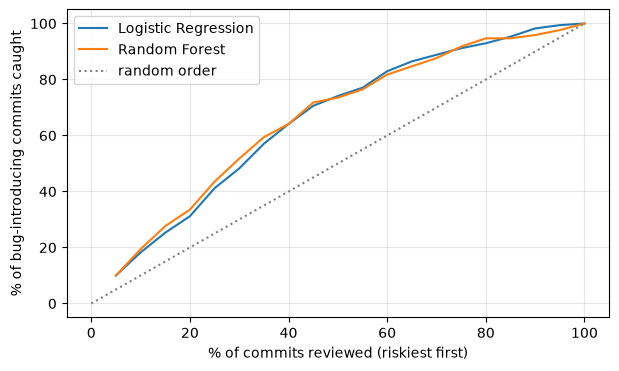

review the riskiest 20% -> catch 34% of the bugs
review the riskiest 30% -> catch 52% of the bugs
review the riskiest 50% -> catch 74% of the bugs


In [8]:
fractions = np.linspace(0.05, 1, 20)
for name, r in risk.items():
    plt.plot(fractions * 100, [bugs_caught(y_test, r, f) * 100 for f in fractions], label=name)
plt.plot([0, 100], [0, 100], ls=":", color="gray", label="random order")
plt.xlabel("% of commits reviewed (riskiest first)")
plt.ylabel("% of bug-introducing commits caught")
plt.legend()
plt.show()

for f in (0.2, 0.3, 0.5):
    caught = bugs_caught(y_test, risk["Random Forest"], f)
    print(f"review the riskiest {f:.0%} -> catch {caught:.0%} of the bugs")

## 8. A critical look at `lines_added`

Permutation importance says `lines_added` dominates. Part of that is real, but SZZ also has a
built-in size bias: the more lines a commit writes, the more lines a future fix can touch.
Removing the feature shows how much signal the others carry on their own.

In [9]:
without = [c for c in X_train.columns if c != "lines_added"]
model = build_forest().fit(X_train[without], y_train)
auc_without = roc_auc_score(y_test, model.predict_proba(X_test[without])[:, 1])

print(f"with lines_added:    AUC = {roc_auc_score(y_test, risk['Random Forest']):.3f}")
print(f"without lines_added: AUC = {auc_without:.3f}")

with lines_added:    AUC = 0.759
without lines_added: AUC = 0.734


The AUC drops only from about 0.76 to 0.73: the other features (lines deleted, files, history of
the touched files) still carry most of the signal, so the model is not just counting lines.

## Conclusions

- About half of the bug-introducing commits are caught by reviewing the riskiest 30%.
- The evaluation is honest: temporal split (a random split would overstate AUC by ~0.07),
  immature labels removed, features computed from the past only.
- A logistic regression is as good as a Random Forest here, which makes a browser demo possible.
- Limitations: SZZ labels are noisy, size bias exists, and the model was trained on one
  repository. It ranks risk; it does not find bugs. Code review still sees what the model cannot.